# B03-KM — KMeans trên RFM (Yeo–Johnson + Standard + PCA 90%)

Thí nghiệm **B03-KM** (người chạy: An) theo chiến lược model. So với B01, **thay `log1p` bằng Yeo–Johnson** (`standardize=False`, tự fit lambda) trước khi `StandardScaler` → PCA 90% → K-Means. Yeo–Johnson tổng quát hơn log1p (log1p là Box–Cox dịch +1 cho dữ liệu dương; Yeo–Johnson học lambda tối ưu riêng cho từng biến, xử lý được cả giá trị 0).

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary"]
K_GRID = range(2, 11)
RANDOM_STATE = 42
N_INIT = 20         # giống A03-KM, A02-KM
PCA_VAR = 0.90

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)

Dữ liệu đầu vào: (4327, 3)


**Nhận xét:** Cùng 4.327 khách, cùng file feature chung của nhóm.

## Yeo–Johnson (standardize=False) rồi chuẩn hóa, PCA 90%

`standardize=False` để tự quản bước `StandardScaler` riêng, tách rõ hai bước biến đổi và chuẩn hóa (giống cấu trúc B01, B04).

In [3]:
pt = PowerTransformer(method="yeo-johnson", standardize=False)
X_t = pt.fit_transform(X)
lambdas = dict(zip(FEATURES, pt.lambdas_.round(4)))
print("Lambda đã fit:", lambdas)
print(pd.DataFrame({"skew_raw": X.skew().round(2),
                     "skew_yeo_johnson": pd.DataFrame(X_t, columns=FEATURES).skew().round(2)}))

X_scaled = StandardScaler().fit_transform(X_t)
cum = np.cumsum(PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

Lambda đã fit: {'Recency': np.float64(0.1252), 'Frequency': np.float64(-0.7704), 'Monetary': np.float64(-0.0783)}
           skew_raw  skew_yeo_johnson
Recency        1.25             -0.05
Frequency     11.95              0.22
Monetary      21.04             -0.01
Phương sai tích lũy: [0.7472 0.9334 1.    ]
Số PC giữ lại: 2 / 3 (phương sai giữ 93.34%)


**Nhận xét:** Yeo–Johnson đưa skew về gần 0 cho cả ba biến (Recency −0,05, Frequency 0,22, Monetary −0,01) — tốt hơn log1p (B01: Recency −0,33, Frequency 1,21, Monetary 0,35), vì lambda được fit riêng cho từng biến thay vì dùng chung công thức log1p. PCA 90% vẫn chỉ cần 2/3 PC (giữ 93,34%, gần với B01 là 94,01%).

## Quét số cụm k

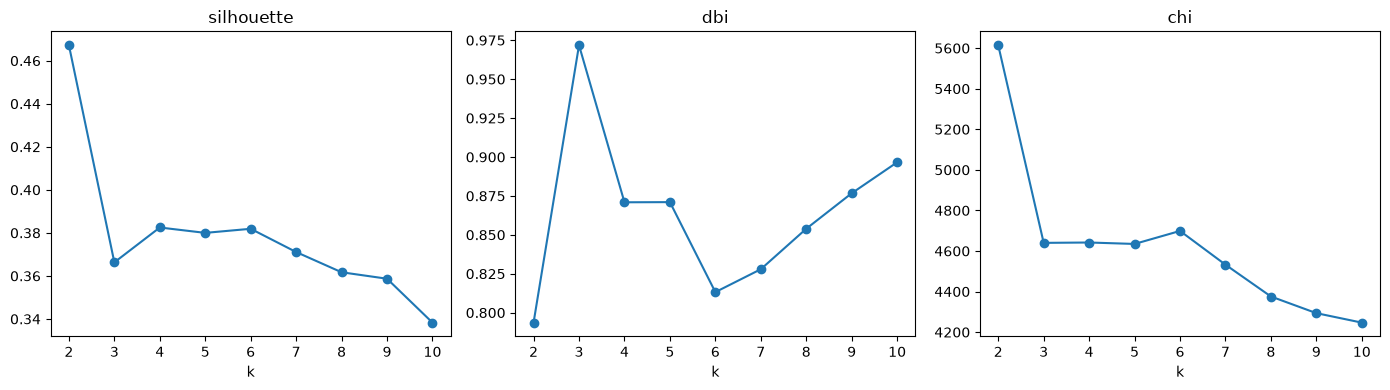

,k,silhouette,dbi,chi,inertia,min_cluster
0,2,0.4672,0.7936,5614.6,5272.5,1997
1,3,0.3663,0.9718,4640.1,3851.3,1143
2,4,0.3825,0.8709,4641.9,2870.6,887
3,5,0.3800,0.8710,4634.8,2290.8,792
4,6,0.3819,0.8132,4698.9,1882.3,625
5,7,0.3711,0.8279,4532.5,1661.0,361
6,8,0.3617,0.8539,4375.7,1497.4,331
7,9,0.3587,0.8767,4293.6,1353.1,321
8,10,0.3383,0.8966,4246.9,1229.7,308


In [4]:
rows = []
for k in K_GRID:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    rows.append({"k": k, "silhouette": round(silhouette_score(Z, km.labels_), 4),
                 "dbi": round(davies_bouldin_score(Z, km.labels_), 4),
                 "chi": round(calinski_harabasz_score(Z, km.labels_), 1),
                 "inertia": round(km.inertia_, 1),
                 "min_cluster": int(np.bincount(km.labels_).min())})
metrics = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["silhouette", "dbi", "chi"]):
    ax.plot(metrics["k"], metrics[col], marker="o")
    ax.set_xlabel("k"); ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG / "kmeans_metrics_by_k.png", dpi=150); plt.show()
metrics

**Nhận xét:** Silhouette cao nhất ở **k=2 (0,4672)**, khác hẳn mẫu đã gặp ở A01/A02-KM/A04-DB (nơi k=2 luôn là tách 24 khách ngoại lai khỏi 4.303 khách — lệch gần tuyệt đối). Ở đây cần xem kích thước cụm thực tế mới biết có phải phân khúc cân đối hay không.

## Chọn k và huấn luyện mô hình cuối

In [5]:
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("k được chọn (Silhouette lớn nhất):", best_k)

model = Pipeline([("power", PowerTransformer(method="yeo-johnson", standardize=False)),
                   ("scaler", StandardScaler()),
                   ("pca", PCA(n_components=n_pc, svd_solver="full")),
                   ("kmeans", KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT))]).fit(X)
labels = model["kmeans"].labels_
assert (model[:-1].transform(X) == Z).all()
print(pd.Series(labels).value_counts().sort_index().rename("Số khách"))

k được chọn (Silhouette lớn nhất): 2
0    1997
1    2330
Name: Số khách, dtype: int64


**Nhận xét:** k=2 chia **1.997 và 2.330 khách (46,2% / 53,8%)** — lần đầu tiên trong toàn bộ nhóm A và B, k theo Silhouette lớn nhất cho ra **phân khúc cân đối thật sự**, không phải tách ngoại lai.

## Đối chiếu B01-GN và A03-KM

B03 đổi biến đổi (Yeo–Johnson thay log1p) trên cùng pipeline KMeans như A03 (PCA cố định 2 — ở đây PCA theo ngưỡng 90% tự ra 2 PC, trùng số chiều với A03). Dựng lại B01 bằng KMeans (log1p) để so cùng điều kiện.

In [6]:
X_b01 = np.log1p(X)
Z_b01 = PCA(n_components=PCA_VAR, svd_solver="full").fit_transform(StandardScaler().fit_transform(X_b01))
labels_b01_km = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(Z_b01)

Z_a03 = PCA(n_components=2, svd_solver="full").fit_transform(StandardScaler().fit_transform(X))
labels_a03 = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(Z_a03)

print("Số PC: B03 =", Z.shape[1], "| B01 (log1p, dựng lại) =", Z_b01.shape[1], "| A03 =", Z_a03.shape[1])
print("ARI (B03-KM vs B01 bằng KMeans, k cố định =", best_k, "):",
      round(adjusted_rand_score(labels, labels_b01_km), 4))
print("ARI (B03-KM vs A03-KM, k cố định =", best_k, "):",
      round(adjusted_rand_score(labels, labels_a03), 4))

Số PC: B03 = 2 | B01 (log1p, dựng lại) = 2 | A03 = 2
ARI (B03-KM vs B01 bằng KMeans, k cố định = 2 ): 0.7126
ARI (B03-KM vs A03-KM, k cố định = 2 ): 0.002


**Nhận xét:** So với B01 (log1p) ở cùng k=2 bằng KMeans: ARI = 0,7126 — khá giống nhau, hai cách biến đổi đều tách được nhóm giá trị cao/thấp theo hướng tương tự. So với A03-KM (không biến đổi) ở cùng k=2: ARI chỉ **0,0020** — gần như độc lập, xác nhận đây không phải là kiểu tách ngoại lai của A03 mà là một cách chia hoàn toàn khác.

## Hồ sơ cụm

In [7]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"),
    Frequency=("Frequency", "median"), Monetary=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,1997,20.0,5.0,1698.9,46.2,88.2
1,2330,117.0,1.0,318.3,53.8,11.8


**Nhận xét:** Cụm 0 (1.997 khách, 46,2%) mua gần đây, thường xuyên, chi tiêu cao (Recency 20, Frequency 5, Monetary 1.699) — chiếm **88,2% Monetary**. Cụm 1 (2.330 khách, 53,8%) mua một lần, lâu chưa quay lại (Recency 117, Frequency 1, Monetary 318) — chỉ 11,8% Monetary. Đây là ranh giới khách giá trị cao/thấp rõ ràng, đúng mục tiêu đồ án.

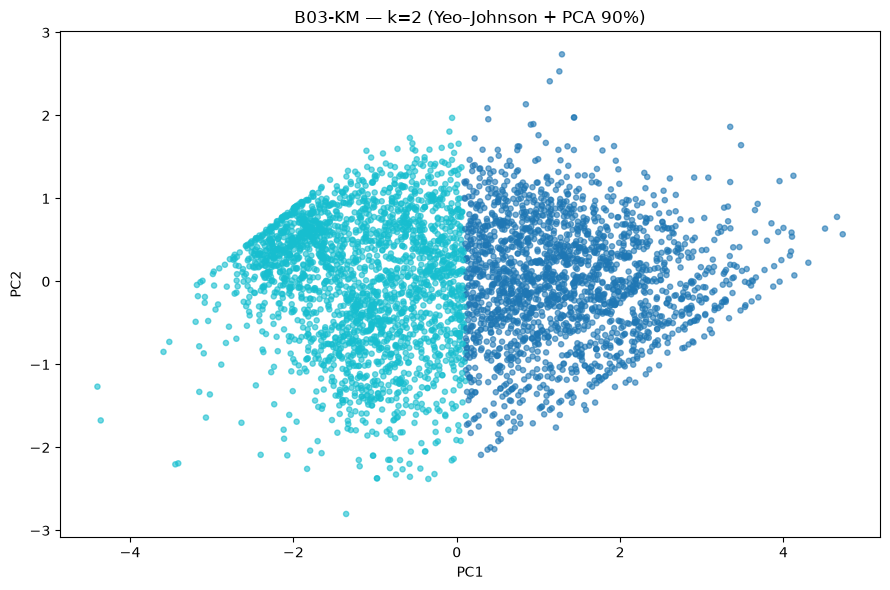

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=14, alpha=0.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"B03-KM — k={best_k} (Yeo–Johnson + PCA 90%)")
plt.tight_layout(); plt.savefig(FIG / "kmeans_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Hai cụm tách thành hai khối rõ rệt trên mặt phẳng PC1–PC2, không còn hình chữ V dồn về một góc như ở RFM thô (A01/A03) — Yeo–Johnson đã làm phẳng phân phối đủ để khoảng cách Euclid phản ánh đúng sự khác biệt giữa hai nhóm khách.

## Lưu kết quả (kèm lambda đã fit)

In [9]:
metrics.to_csv(OUT / "kmeans_b03_metrics_by_k.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "kmeans_b03_labels.csv", index=False)
joblib.dump(model, "kmeans_b03_model.pkl")
params = {"experiment": "B03-KM", "features": FEATURES, "transform": "yeo-johnson(standardize=False)",
          "lambdas": {k: float(v) for k, v in lambdas.items()}, "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "k": best_k, "silhouette": float(metrics.loc[metrics.k == best_k, "silhouette"].iloc[0]),
          "dbi": float(metrics.loc[metrics.k == best_k, "dbi"].iloc[0]),
          "chi": float(metrics.loc[metrics.k == best_k, "chi"].iloc[0]),
          "ari_vs_b01_log1p_km": float(adjusted_rand_score(labels, labels_b01_km)),
          "ari_vs_a03_km": float(adjusted_rand_score(labels, labels_a03))}
json.dump(params, open(OUT / "kmeans_b03_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['kmeans_b03_labels.csv', 'kmeans_b03_metrics_by_k.csv', 'kmeans_b03_params.json']


**Nhận xét kết luận B03-KM:** Đây là kết quả tốt nhất trong toàn bộ nhóm A/B tính đến nay — k=2 theo đúng quy tắc Silhouette lớn nhất (không cần nới lỏng điều kiện) cho ra 2 cụm cân đối (46%/54%) với ranh giới Monetary rõ (88,2% so với 11,8%), đúng kỳ vọng đề tài 'khách hàng giá trị cao'. Khác B01 (log1p, ARI=0,71 — gần giống) nhưng khác hẳn A03/A01 (không biến đổi, ARI≈0). Nên đề xuất B03 (Yeo–Johnson) hoặc B01 (log1p) làm ứng viên chính cho mô hình KMeans cuối cùng, thay vì nhánh A (RFM thô).